# Dividing the score by each recording's noise floor, on the poke run

**The question:** since 23 October 2026 `outline_variability` is divided by the recording's noise floor at the mite (`Analyzer.plate_noise()`: the variance over the frames of the bare plate at the patch's edge), so it is in multiples of the noise rather than grey levels squared. Does that separate the recordings labelled moving from those labelled still better than the score before (`raw` = score × floor)? And what threshold does the score need?

**The data:** only the poke run `poke_test_oct` (a live run of 22–23 October 2026), the one hand-labelled dataset recorded as live runs now record, 3 s at 30 fps (90 frames). The earlier datasets are other lengths and are left out as not representative. 14 mites on two plates, 95 recordings over 15.7 h, 22 of them labelled.

`scripts/noise_floor.py` cut every mite in every recording as a calibration report does (the mite's box where it was found, stabilized, the metric's pad) and kept `raw`, `noise` and `score` (`results/scripts/noise_floor.csv.gz`); this notebook only reads that. The run sits one folder too deep in `recordings/` (`poke_test_oct/poke_test_oct`), so the script read a hard-linked copy: `python scripts/noise_floor.py --root %TEMP%/zzrc/gt --add`.

Dividing all of a recording's scores by one number cannot change how they rank; the division can only matter where the floor differs **between mites, or over the run**. Section 2 measures how much it does.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("DISCOBOX_CONFIG", str(ROOT / "config.default.yaml"))  # the defaults, only read
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classes.ground_truth import calibration
from noise_floor import OUT

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

POKE = "poke_test_oct"
SCORES = {"raw": "raw (grey levels²)", "score": "score (× noise floor)"}
APP_THRESHOLD = 0.088   # the calibration report's suggestion on this run (section 5)

everything = pd.read_csv(OUT, dtype={"mite": str})   # as text: mite 7.10 is not 7.1
run = everything[everything["dataset"] == POKE].astype({"labelled": bool, "moving": bool})
# A mite counted dead is no longer saved, nor one added later before it was: its patch is empty
recorded = run[(run["noise"] > 0) | (run["raw"] > 0)]
labelled = recorded[recorded["labelled"]]
print(f"{run['mite'].nunique()} mites, {run['recording'].nunique()} recordings over {run['minutes'].max() / 60:.1f} h; "
      f"{len(recorded)} of {len(run)} mite-recordings recorded, {len(labelled)} labelled "
      f"({labelled['moving'].sum()} moving, {(~labelled['moving']).sum()} still)")
recorded.assign(labelled_moving=recorded["labelled"] & recorded["moving"]).groupby("mite").agg(
    recorded=("recording", "size"), first=("recording", "min"), last=("recording", "max"),
    labelled=("labelled", "sum"), moving=("labelled_moving", "sum"))

14 mites, 95 recordings over 15.7 h; 1049 of 1330 mite-recordings recorded, 304 labelled (204 moving, 100 still)


,recorded,first,last,labelled,moving
mite,,,,,
13.1,66,1,66,21,10
13.2,65,1,65,21,11
13.3,66,1,66,21,10
13.4,86,1,86,21,11
7.1,56,0,55,22,16
7.10,69,0,68,22,18
7.2,59,0,58,22,21
7.3,87,0,86,22,12
7.4,93,0,92,22,21


## 1. How much does the noise floor vary?

Per mite over the run, and per recording (median over the mites recorded in it) against time. If the floor held still, dividing by it would only rescale every score alike.

In [2]:
per_mite = recorded.groupby("mite")["noise"].describe(percentiles=[0.05, 0.5, 0.95])[["5%", "50%", "95%"]]
per_mite.loc["whole run"] = recorded["noise"].quantile([0.05, 0.5, 0.95]).to_numpy()
per_mite["95% / 5%"] = per_mite["95%"] / per_mite["5%"]
per_mite

,5%,50%,95%,95% / 5%
mite,,,,
13.1,2.448,2.537,2.764,1.129
13.2,2.471,2.510,2.664,1.078
13.3,2.513,2.651,2.745,1.092
13.4,2.568,2.672,2.732,1.064
7.1,2.668,2.694,2.852,1.069
7.10,2.655,2.713,2.969,1.118
7.2,2.687,2.732,2.979,1.109
7.3,2.701,2.894,3.030,1.122
7.4,2.702,2.844,2.987,1.105


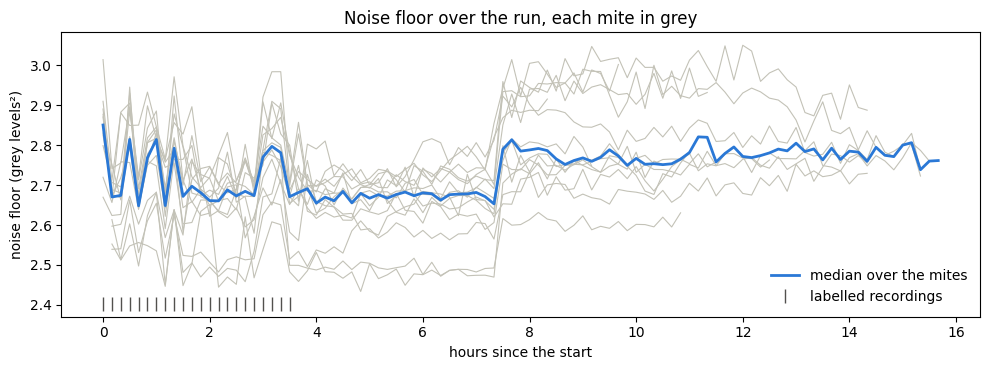

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for mite, part in recorded.groupby("mite"):
    ax.plot(part["minutes"] / 60, part["noise"], color="#c3c2b7", lw=0.8)
median = recorded.groupby("minutes")["noise"].median()
ax.plot(median.index / 60, median, color="#2a78d6", lw=2, label="median over the mites")
marked = labelled.groupby("minutes").size().index
ax.plot(marked / 60, [ax.get_ylim()[0]] * len(marked), "|", color="#52514e", ms=10, label="labelled recordings")
ax.set(xlabel="hours since the start", ylabel="noise floor (grey levels²)", title="Noise floor over the run, each mite in grey")
ax.legend(frameon=False)
plt.tight_layout()

## 2. Does a still mite's score follow its floor?

A still mite's score is what is left of the noise after the outline's cancelling, so `raw` should rise with the floor and `score` should not. Spearman's ρ over the recordings labelled still, and over every recorded one (most of a run is still mites, and dead mites stop being recorded).

In [4]:
def spearman(a, b):
    return float(pd.Series(a).rank().corr(pd.Series(b).rank()))

still = labelled[~labelled["moving"]]
pd.DataFrame({column: {"ρ with the floor, labelled still": spearman(still[column], still["noise"]),
                       "ρ with the floor, every recording": spearman(recorded[column], recorded["noise"])}
              for column in SCORES}).T

,"ρ with the floor, labelled still","ρ with the floor, every recording"
raw,0.095,-0.076
score,0.055,-0.102


## 3. Separation of the labelled recordings

AUC (the chance that a random moving recording scores higher than a random still one), d' (the gap between the means of the log scores of moving and still, in their pooled standard deviation, which does not depend on the scale) and the margin: how far apart, as a factor, the lowest moving and the highest still recordings are (below 1 they overlap).

In [5]:
def separation(part, column):
    log = np.log(part[column].clip(lower=1e-6))
    moving, still = log[part["moving"]], log[~part["moving"]]
    return {"AUC": calibration.auc(part[column], part["moving"]),
            "d'": (moving.mean() - still.mean()) / np.sqrt((moving.var() + still.var()) / 2),
            "lowest moving / highest still": float(np.exp(moving.min() - still.max())),
            "moving below highest still": int((moving < still.max()).sum()),
            "still above lowest moving": int((still > moving.min()).sum())}

pd.DataFrame({column: separation(labelled, column) for column in SCORES}).T

,AUC,d',lowest moving / highest still,moving below highest still,still above lowest moving
raw,0.999,4.626,0.248,4.0,17.0
score,0.999,4.637,0.230,4.0,20.0


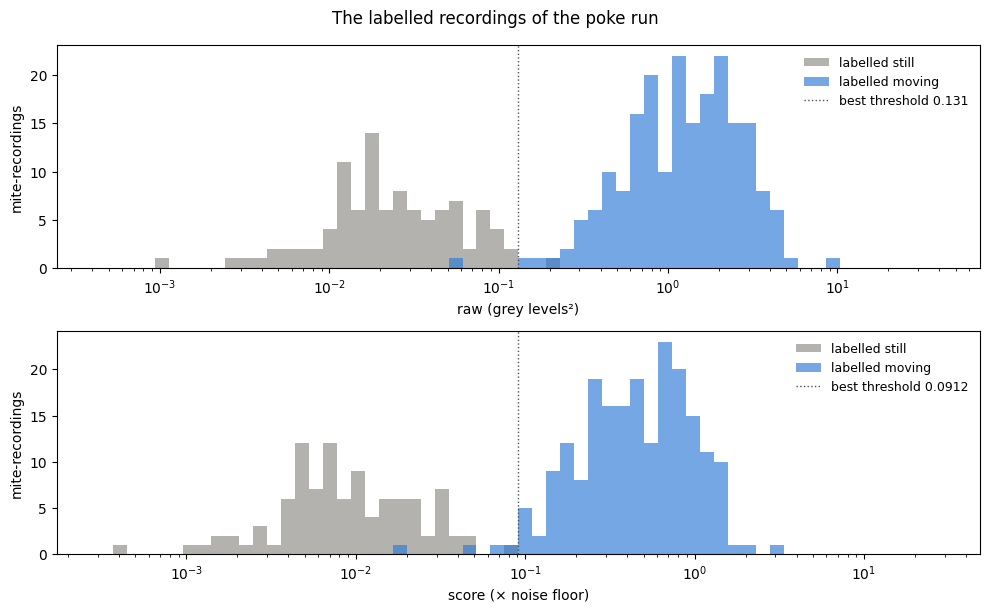

In [6]:
BEST = {column: calibration.best_threshold(labelled[column], labelled["moving"]) for column in SCORES}
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2))
for ax, column in zip(axes, SCORES):
    # each axis spans the same factors round its threshold, so the overlap compares by eye
    bins = np.geomspace(BEST[column] / 300, BEST[column] * 300, 61)
    values = labelled[column].clip(bins[0], bins[-1])
    for moving, colour, label in ((False, "#8a8984", "labelled still"), (True, "#2a78d6", "labelled moving")):
        ax.hist(values[labelled["moving"] == moving], bins=bins, color=colour, alpha=0.65, label=label)
    ax.axvline(BEST[column], color="#52514e", ls=":", lw=1, label=f"best threshold {BEST[column]:.3g}")
    ax.set(xscale="log", xlabel=SCORES[column], ylabel="mite-recordings")
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("The labelled recordings of the poke run")
plt.tight_layout()

## 4. The threshold

The best threshold on the labels (Youden's J) of each score, and the score's at the calibration report's suggestion, **0.088**: the threshold that puts each mite's death at the recording its labels put it (the report of 23 October 2026, run on the copy with `config.default.yaml`: all 14 deaths exact). The default 0.472 was fitted on 10-frame recordings; it puts 6 of the 14 deaths early, by 2.1 recordings on average.

In [7]:
def calls(part, column, threshold):
    c = calibration.confusion(part[column], part["moving"], threshold)
    return {"threshold": threshold, "accuracy": c["accuracy"],
            "still called moving": c["still_called_moving"], "moving called still": c["moving_called_still"]}

pd.DataFrame({"raw, best": calls(labelled, "raw", BEST["raw"]),
              "score, best": calls(labelled, "score", BEST["score"]),
              "score, calibration report": calls(labelled, "score", APP_THRESHOLD),
              "score, default 0.472": calls(labelled, "score", 0.472)}).T

,threshold,accuracy,still called moving,moving called still
"raw, best",0.131,0.993,1.0,1.0
"score, best",0.091,0.987,0.0,4.0
"score, calibration report",0.088,0.987,0.0,4.0
"score, default 0.472",0.472,0.671,0.0,100.0


## 5. Over the whole run

Every recorded mite-recording, labelled or not, called with each score at its best threshold: where the two disagree, and at what floor. A disagreement is a recording whose floor moved it across the threshold.

In [8]:
raw_calls = recorded["raw"] >= BEST["raw"]
score_calls = recorded["score"] >= BEST["score"]
differ = recorded[raw_calls != score_calls].assign(raw_call=raw_calls, score_call=score_calls)
print(f"{len(differ)} of {len(recorded)} calls differ "
      f"({(differ['score_call'] & ~differ['raw_call']).sum()} moving only by the score, "
      f"{(differ['raw_call'] & ~differ['score_call']).sum()} only by raw)")
differ[["mite", "recording", "minutes", "labelled", "moving", "raw", "noise", "score", "raw_call", "score_call"]]

24 of 1049 calls differ (0 moving only by the score, 24 only by raw)


,mite,recording,minutes,labelled,moving,raw,noise,score,raw_call,score_call
17946,7.6,8,80.0,True,True,0.213,2.755,0.077,True,False
17951,13.1,8,80.0,True,False,0.227,2.638,0.086,True,False
17984,7.2,11,110.0,True,True,0.134,2.708,0.050,True,False
18036,13.2,14,140.0,True,True,0.185,2.491,0.074,True,False
18164,13.4,23,230.0,False,False,0.164,2.727,0.060,True,False
18219,13.3,27,270.0,False,False,0.163,2.530,0.064,True,False
18235,7.1,29,290.0,False,False,0.243,2.694,0.090,True,False
18264,7.2,31,310.0,False,False,0.166,2.694,0.062,True,False
18278,7.2,32,320.0,False,False,0.145,2.693,0.054,True,False
18305,7.1,34,340.0,False,False,0.144,2.704,0.053,True,False


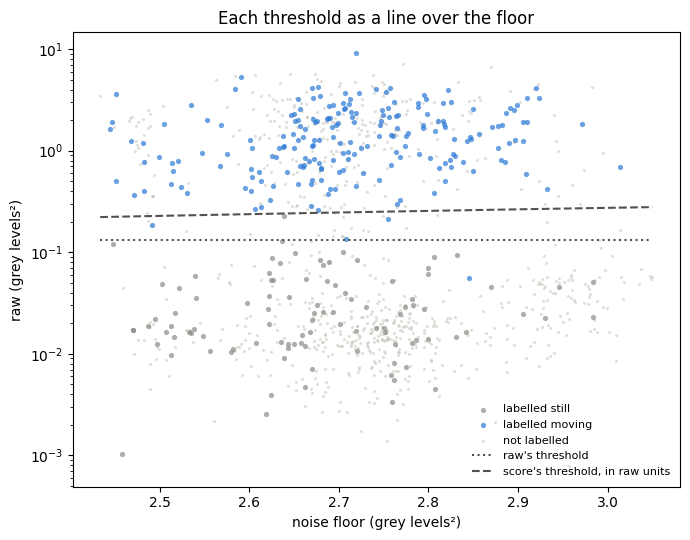

In [9]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for moving, colour, label in ((False, "#8a8984", "labelled still"), (True, "#2a78d6", "labelled moving")):
    part = labelled[labelled["moving"] == moving]
    ax.scatter(part["noise"], part["raw"], s=14, color=colour, alpha=0.7, label=label, linewidths=0)
rest = recorded[~recorded["labelled"]]
ax.scatter(rest["noise"], rest["raw"], s=5, color="#c3c2b7", alpha=0.5, label="not labelled", linewidths=0, zorder=0)
floors = np.linspace(recorded["noise"].min(), recorded["noise"].max(), 50)
ax.plot(floors, [BEST["raw"]] * len(floors), color="#52514e", ls=":", label="raw's threshold")
ax.plot(floors, BEST["score"] * floors, color="#52514e", ls="--", label="score's threshold, in raw units")
ax.set(yscale="log", xlabel="noise floor (grey levels²)", ylabel=SCORES["raw"], title="Each threshold as a line over the floor")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## Findings

**On the poke run, dividing by the noise floor does not separate moving from still any better. It neither helps nor hurts, because the floor hardly varies within the run.**

- **The floor is nearly constant.** Over all 1,049 recorded mite-recordings it lies between 2.50 and 2.96 (5–95%), ±9% round 2.72. Each mite's own floor varies by 6–13%, and the mites' medians lie between 2.51 and 2.89. The one change over time is a step up of about 4% at 7.5 h, after the labelled recordings, which are all in the first 3.5 h (section 1).
- **No score follows the floor.** Even the raw score of a still mite barely rises with its floor (Spearman's ρ 0.10 over the labelled still recordings), so there is little for the division to take out (ρ 0.06 after, section 2). At ±9% the floor is small beside the spread of the still scores themselves: they span two orders of magnitude.
- **The separation is the same.** AUC 0.999 for both, d' 4.63 against 4.64. The overlap is the same 4 moving and about 20 still recordings in both scores, and the margin between the lowest moving and highest still is a factor 0.25 before against 0.23 after (section 3).
- **The calls differ only through where each threshold falls.** At their best thresholds raw makes 2 mistakes on the labels and the score 4. Over the whole run the two disagree on 24 of 1,049 recordings, every one called moving by raw alone, with raw between 0.13 and 0.25. That is the gap between the two best thresholds (raw's 0.131 equals a score of about 0.048; the score's 0.091 equals a raw of about 0.25), not the floor: the dashed line in section 5 is nearly flat. Which of them is right is not settled by 304 labels. 20 of the 24 recordings are unlabelled, and labelling them would settle where the threshold belongs.
- **The threshold for 3 s / 30 fps recordings: 0.088** (the calibration report: all 14 deaths exact; Youden's J on the labels gives 0.091). The default 0.472, fitted on 10-frame recordings, calls 100 of the 204 labelled moving recordings still (section 4) and puts 6 of the 14 deaths early.

**So the division is neutral here.** It would only pay off where the floor differs more, between runs under another light, exposure or camera, and this run alone cannot show that.
